In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('Dataset .csv')

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [5]:
geo_df = df[(df['Longitude'] != 0) & (df['Latitude'] != 0)]

In [7]:
print(geo_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 9052 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9052 non-null   int64  
 1   Restaurant Name       9052 non-null   object 
 2   Country Code          9052 non-null   int64  
 3   City                  9052 non-null   object 
 4   Address               9052 non-null   object 
 5   Locality              9052 non-null   object 
 6   Locality Verbose      9052 non-null   object 
 7   Longitude             9052 non-null   float64
 8   Latitude              9052 non-null   float64
 9   Cuisines              9043 non-null   object 
 10  Average Cost for two  9052 non-null   int64  
 11  Currency              9052 non-null   object 
 12  Has Table booking     9052 non-null   object 
 13  Has Online delivery   9052 non-null   object 
 14  Is delivering now     9052 non-null   object 
 15  Switch to order menu  9052

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

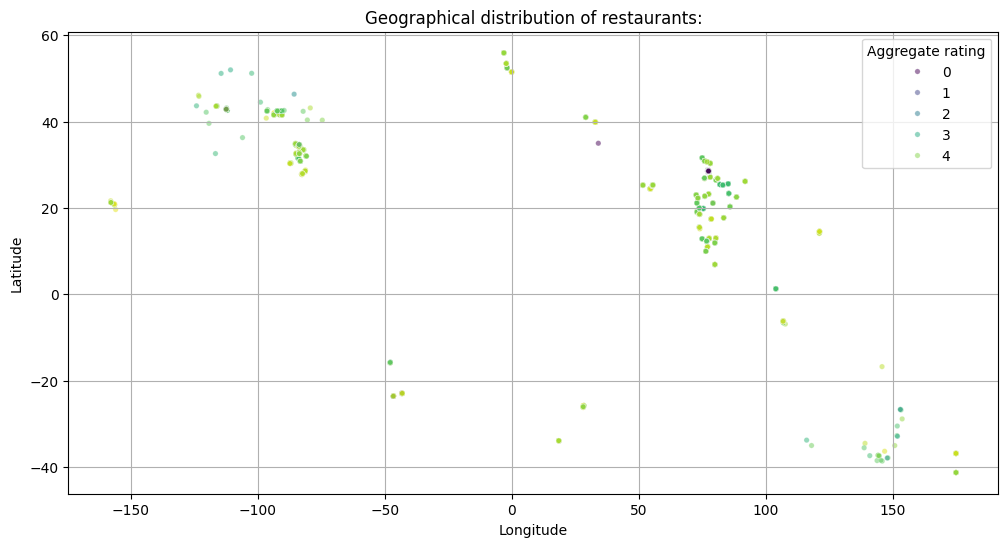

In [10]:
plt.figure(figsize=(12,6))
sns.scatterplot( 
    x = 'Longitude',
    y = 'Latitude',
    data = geo_df,
    alpha = 0.5,
    s = 15,
    hue = 'Aggregate rating',
    palette = 'viridis'
)
plt.title('Geographical distribution of restaurants:')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()

In [11]:
top_cities = df['City'].value_counts().head(10)
print('top 10 cities by concentration :\n', top_cities)

top 10 cities by concentration :
 City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Bhubaneshwar      21
Lucknow           21
Ahmedabad         21
Amritsar          21
Guwahati          21
Name: count, dtype: int64


In [12]:
top_localities = df['Locality'].value_counts().head(10)
print('top 10 Localities by concentration :\n', top_localities)

top 10 Localities by concentration :
 Locality
Connaught Place        122
Rajouri Garden          99
Shahdara                87
Defence Colony          86
Malviya Nagar           85
Pitampura               85
Mayur Vihar Phase 1     84
Rajinder Nagar          81
Safdarjung              80
Satyaniketan            79
Name: count, dtype: int64


In [15]:
top_cities_list = top_cities.index.tolist()
filtered_df = df[df['City'].isin(top_cities_list)]
print(filtered_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 8052 entries, 644 to 9112
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         8052 non-null   int64  
 1   Restaurant Name       8052 non-null   object 
 2   Country Code          8052 non-null   int64  
 3   City                  8052 non-null   object 
 4   Address               8052 non-null   object 
 5   Locality              8052 non-null   object 
 6   Locality Verbose      8052 non-null   object 
 7   Longitude             8052 non-null   float64
 8   Latitude              8052 non-null   float64
 9   Cuisines              8052 non-null   object 
 10  Average Cost for two  8052 non-null   int64  
 11  Currency              8052 non-null   object 
 12  Has Table booking     8052 non-null   object 
 13  Has Online delivery   8052 non-null   object 
 14  Is delivering now     8052 non-null   object 
 15  Switch to order menu  80

In [16]:
city_stats = filtered_df.groupby('City').agg({
    'Aggregate rating' : 'mean',
    'Price range' : 'mean',
    'Average Cost for two' : 'mean',
    'Restaurant ID' : 'count'
}).rename(columns={'Restaurant ID' : 'Restaurant Count'})

city_stats = city_stats.sort_values(by = 'Restaurant Count',ascending = False)
print(city_stats)
    
    

              Aggregate rating  Price range  Average Cost for two  \
City                                                                
New Delhi             2.438845     1.621597            596.088069   
Gurgaon               2.651431     1.855993            714.016100   
Noida                 2.036204     1.601852            539.490741   
Faridabad             1.866932     1.454183            447.609562   
Ghaziabad             2.852000     1.800000            602.000000   
Ahmedabad             4.161905     2.571429            857.142857   
Amritsar              3.685714     1.809524            480.952381   
Bhubaneshwar          3.980952     1.857143            678.571429   
Lucknow               4.195238     2.571429            859.523810   
Guwahati              4.190476     2.523810            821.428571   

              Restaurant Count  
City                            
New Delhi                 5473  
Gurgaon                   1118  
Noida                     1080  
Farida

In [18]:
target_city_df = df[df['City'] == 'New Delhi']

locality_stats = target_city_df.groupby('Locality').agg({
    'Aggregate rating' : 'mean',
    'Price range' : 'mean',
    'Restaurant ID' : 'count'
}).sort_values(by = 'Restaurant ID', ascending = False).head(10)

print('Insights for top localities in New Delhi:\n',locality_stats)

Insights for top localities in New Delhi:
                      Aggregate rating  Price range  Restaurant ID
Locality                                                         
Connaught Place              3.686885     2.598361            122
Rajouri Garden               3.591919     2.202020             99
Shahdara                     1.413793     1.137931             87
Defence Colony               3.210465     1.930233             86
Pitampura                    2.870588     1.470588             85
Malviya Nagar                3.417857     1.773810             84
Mayur Vihar Phase 1          2.026190     1.297619             84
Rajinder Nagar               2.943210     1.432099             81
Safdarjung                   2.801250     1.675000             80
Satyaniketan                 3.482278     1.620253             79
